# Practical 3: Image Classification with CNNs (CIFAR-10)
**Name:** Aditya Ganeshe  **PRN:** 202301070142   

**Preprocessing:** pixels scaled to 0-1, then standardized with training mean/std.
**Train/test strategy:** 50,000 train images (45,000 train + 5,000 validation), 10,000 test images kept untouched until final evaluation.
**Loss/optimizer:** sparse categorical cross-entropy, Adam. **Random seed:** 42.



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

# reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load the data

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1634s 10us/step
Train: (50000, 32, 32, 3) (50000,)
Test : (10000, 32, 32, 3) (10000,)


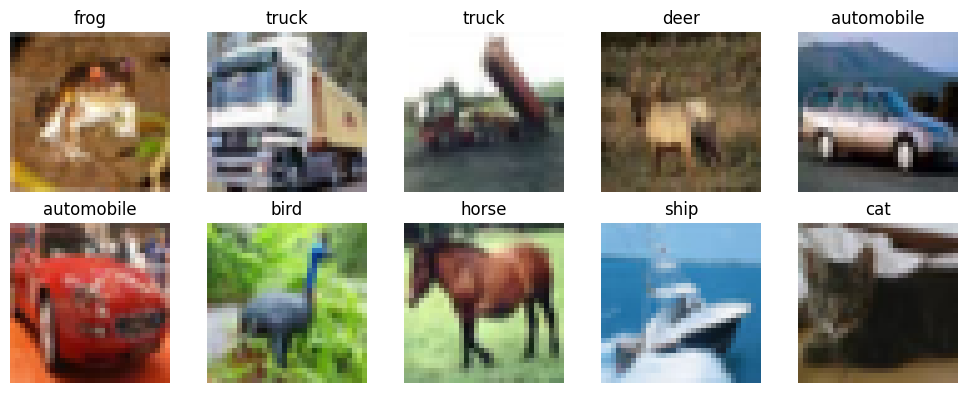

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("Train:", x_train.shape, y_train.shape)
print("Test :", x_test.shape, y_test.shape)

# quick look at some images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
# Scale pixels to 0-1 range
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Normalize with training mean/std (helps training converge faster)
mean = x_train.mean(axis=(0, 1, 2), keepdims=True)
std = x_train.std(axis=(0, 1, 2), keepdims=True)
x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

# Hold out 5000 training images for validation
x_val, y_val = x_train[-5000:], y_train[-5000:]
x_tr, y_tr = x_train[:-5000], y_train[:-5000]
print("Train:", x_tr.shape, "Val:", x_val.shape, "Test:", x_test.shape)

Train: (45000, 32, 32, 3) Val: (5000, 32, 32, 3) Test: (10000, 32, 32, 3)


## 2. Helper functions (plots + evaluation)

In [4]:
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history['accuracy'], label='train')
    ax[0].plot(history.history['val_accuracy'], label='val')
    ax[0].set_title(title + ' - Accuracy')
    ax[0].set_xlabel('Epoch'); ax[0].legend()

    ax[1].plot(history.history['loss'], label='train')
    ax[1].plot(history.history['val_loss'], label='val')
    ax[1].set_title(title + ' - Loss')
    ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.show()


def evaluate_model(model, name):
    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    print(f"{name} -> Test accuracy: {acc*100:.2f}%  |  Test loss: {loss:.4f}")

    y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.show()

    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))
    return acc

## 3. Baseline CNN

- **Conv2D:** learnable 3x3 filters slide over the image and produce feature maps (shared weights detect the same pattern anywhere in the image).
- **ReLU:** adds non-linearity so the network can learn complex patterns.
- **MaxPooling2D (2x2):** keeps the strongest activation in each 2x2 region, halving height and width (less computation, small shift robustness).
- **Flatten + Dense:** converts feature maps into a vector and combines the features.
- **Softmax output (10 units):** gives class probabilities that sum to 1.

In [5]:
def build_baseline(dropout=0.0, augment=False):
    # same baseline architecture; dropout / augmentation can be switched on for experiments
    inputs = layers.Input(shape=(32, 32, 3))
    x = inputs
    if augment:
        x = layers.RandomFlip('horizontal')(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation='relu')(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(10, activation='softmax')(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

tf.random.set_seed(42)
baseline = build_baseline()
baseline.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
704/704 - 23s - 32ms/step - accuracy: 0.5180 - loss: 1.3469 - val_accuracy: 0.6208 - val_loss: 1.0650
Epoch 2/15
704/704 - 3s - 5ms/step - accuracy: 0.6804 - loss: 0.9206 - val_accuracy: 0.6992 - val_loss: 0.8680
Epoch 3/15
704/704 - 3s - 4ms/step - accuracy: 0.7370 - loss: 0.7541 - val_accuracy: 0.7192 - val_loss: 0.8224
Epoch 4/15
704/704 - 4s - 5ms/step - accuracy: 0.7801 - loss: 0.6389 - val_accuracy: 0.7202 - val_loss: 0.8426
Epoch 5/15
704/704 - 3s - 4ms/step - accuracy: 0.8103 - loss: 0.5491 - val_accuracy: 0.7256 - val_loss: 0.8863
Epoch 6/15
704/704 - 3s - 4ms/step - accuracy: 0.8336 - loss: 0.4771 - val_accuracy: 0.7266 - val_loss: 0.9508
Epoch 7/15
704/704 - 3s - 4ms/step - accuracy: 0.8547 - loss: 0.4136 - val_accuracy: 0.7172 - val_loss: 1.0529
Epoch 8/15
704/704 - 4s - 5ms/step - accuracy: 0.8746 - loss: 0.3555 - val_accuracy: 0.7142 - val_loss: 1.1488
Epoch 9/15
704/704 - 3s - 4ms/step - accuracy: 0.8871 - loss: 0.3141 - val_accuracy: 0.6836 - val_loss: 1.3763

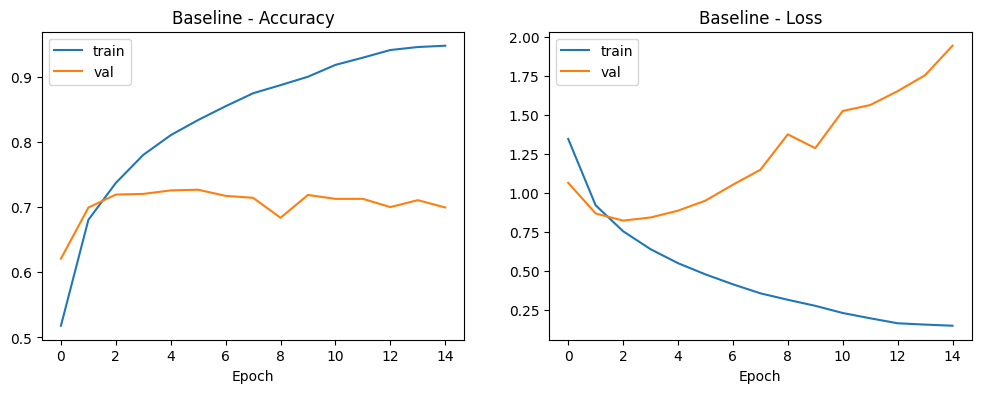

Baseline CNN -> Test accuracy: 69.07%  |  Test loss: 1.9534


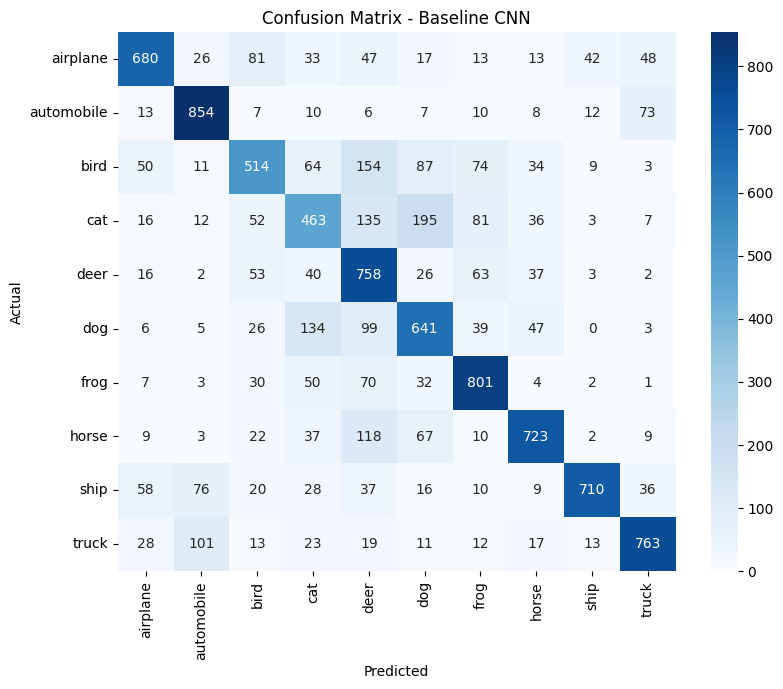

              precision    recall  f1-score   support

    airplane      0.770     0.680     0.722      1000
  automobile      0.781     0.854     0.816      1000
        bird      0.628     0.514     0.565      1000
         cat      0.525     0.463     0.492      1000
        deer      0.525     0.758     0.621      1000
         dog      0.583     0.641     0.611      1000
        frog      0.720     0.801     0.758      1000
       horse      0.779     0.723     0.750      1000
        ship      0.892     0.710     0.791      1000
       truck      0.807     0.763     0.785      1000

    accuracy                          0.691     10000
   macro avg      0.701     0.691     0.691     10000
weighted avg      0.701     0.691     0.691     10000



In [6]:
hist_base = baseline.fit(x_tr, y_tr,
                         epochs=15, batch_size=64,
                         validation_data=(x_val, y_val),
                         verbose=2)
plot_history(hist_base, 'Baseline')
base_acc = evaluate_model(baseline, 'Baseline CNN')

### Misclassified examples (Q1)

Total misclassified: 3093 out of 10000


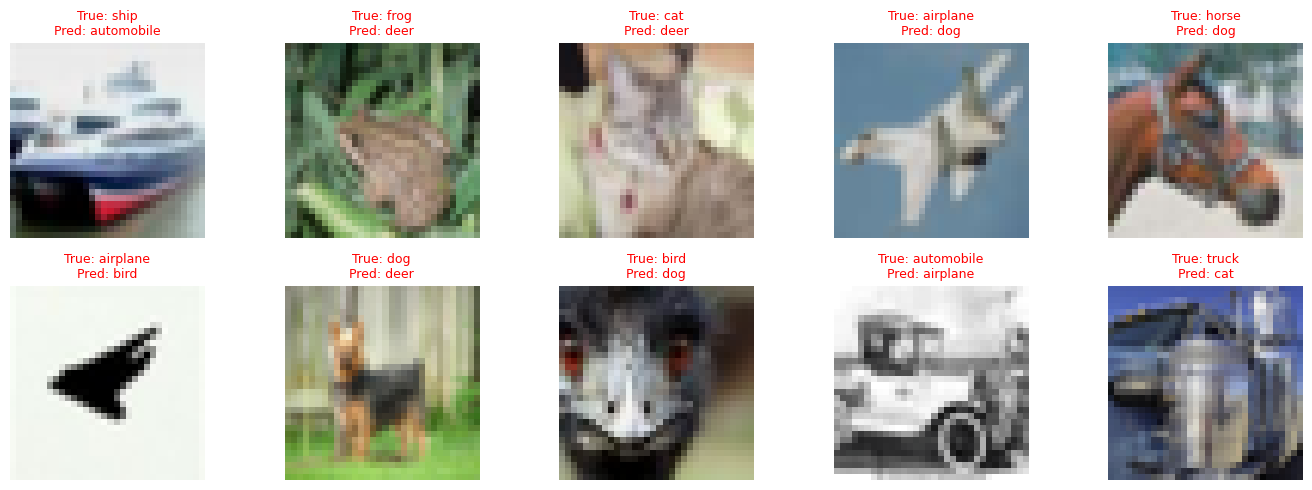

In [7]:
def show_misclassified(model, n=10):
    pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
    wrong = np.where(pred != y_test)[0]
    print(f"Total misclassified: {len(wrong)} out of {len(y_test)}")
    chosen = wrong[:n]
    imgs = np.clip(x_test[chosen] * std + mean, 0, 1)  # undo normalization
    plt.figure(figsize=(14, 5))
    for k, idx in enumerate(chosen):
        plt.subplot(2, 5, k + 1)
        plt.imshow(imgs[k])
        plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[pred[idx]]}",
                  color='red', fontsize=9)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

show_misclassified(baseline, n=10)

## 3b. Regularization experiment on the baseline (Q2)

To see the effect of **one technique at a time**, the same baseline is retrained with (a) dropout only and (b) data augmentation only, using the same epochs and seed.

Epoch 1/15
704/704 - 10s - 14ms/step - accuracy: 0.4237 - loss: 1.5828 - val_accuracy: 0.5890 - val_loss: 1.1657
Epoch 2/15
704/704 - 3s - 5ms/step - accuracy: 0.5700 - loss: 1.2135 - val_accuracy: 0.6664 - val_loss: 0.9746
Epoch 3/15
704/704 - 4s - 5ms/step - accuracy: 0.6309 - loss: 1.0497 - val_accuracy: 0.6920 - val_loss: 0.9008
Epoch 4/15
704/704 - 3s - 4ms/step - accuracy: 0.6695 - loss: 0.9399 - val_accuracy: 0.7116 - val_loss: 0.8536
Epoch 5/15
704/704 - 3s - 4ms/step - accuracy: 0.6967 - loss: 0.8588 - val_accuracy: 0.7182 - val_loss: 0.8506
Epoch 6/15
704/704 - 3s - 5ms/step - accuracy: 0.7211 - loss: 0.7893 - val_accuracy: 0.7246 - val_loss: 0.8347
Epoch 7/15
704/704 - 4s - 5ms/step - accuracy: 0.7451 - loss: 0.7270 - val_accuracy: 0.7288 - val_loss: 0.8515
Epoch 8/15
704/704 - 3s - 4ms/step - accuracy: 0.7605 - loss: 0.6733 - val_accuracy: 0.7340 - val_loss: 0.8179
Epoch 9/15
704/704 - 3s - 4ms/step - accuracy: 0.7770 - loss: 0.6275 - val_accuracy: 0.7320 - val_loss: 0.8687

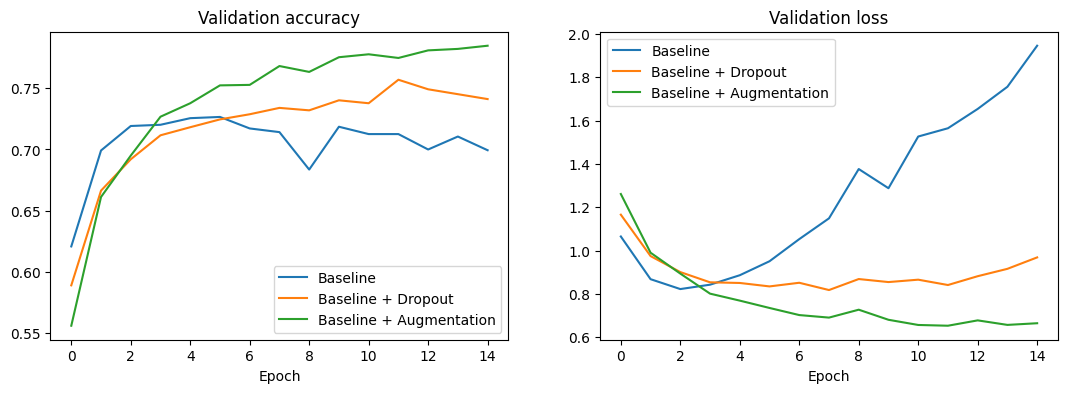

Baseline                  test acc: 69.07%   train-val gap: 24.82%
Baseline + Dropout        test acc: 73.51%   train-val gap: 9.98%
Baseline + Augmentation   test acc: 78.20%   train-val gap: 0.85%


In [8]:
experiments = {
    'Baseline': (baseline, hist_base),
}

tf.random.set_seed(42)
m_drop = build_baseline(dropout=0.4)
h_drop = m_drop.fit(x_tr, y_tr, epochs=15, batch_size=64,
                    validation_data=(x_val, y_val), verbose=2)
experiments['Baseline + Dropout'] = (m_drop, h_drop)

tf.random.set_seed(42)
m_aug = build_baseline(augment=True)
h_aug = m_aug.fit(x_tr, y_tr, epochs=15, batch_size=64,
                  validation_data=(x_val, y_val), verbose=2)
experiments['Baseline + Augmentation'] = (m_aug, h_aug)

# learning curves side by side
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, (m, h) in experiments.items():
    ax[0].plot(h.history['val_accuracy'], label=name)
    ax[1].plot(h.history['val_loss'], label=name)
ax[0].set_title('Validation accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].set_title('Validation loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.show()

# train/val gap (overfitting indicator) and test accuracy
for name, (m, h) in experiments.items():
    t_acc = m.evaluate(x_test, y_test, verbose=0)[1]
    gap = h.history['accuracy'][-1] - h.history['val_accuracy'][-1]
    print(f"{name:25s} test acc: {t_acc*100:.2f}%   train-val gap: {gap*100:.2f}%")

## 4. Improved CNN

What I changed and why:
- **Deeper network** with 2 conv layers per block (3 blocks: 64 -> 128 -> 256 filters)
- **Batch Normalization** for stable and faster training
- **Dropout** (increasing per block) to reduce overfitting
- **Data augmentation** (flip, shift, small rotation) so the model sees more variety
- **L2 weight decay** as light regularization
- **ReduceLROnPlateau + EarlyStopping** to tune the learning rate automatically
- **Global Average Pooling** instead of a huge Flatten layer

In [9]:
from tensorflow.keras import regularizers

def conv_block(x, filters, dropout):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False,
                          kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return x

def build_improved(lr=1e-3):
    # augmentation is only active during training
    augment = keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomRotation(0.05),
    ], name='augmentation')

    inputs = layers.Input(shape=(32, 32, 3))
    x = augment(inputs)
    x = conv_block(x, 64, 0.2)
    x = conv_block(x, 128, 0.3)
    x = conv_block(x, 256, 0.4)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

improved = build_improved()
improved.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,216,458 (4.64 MB)

 Trainable params: 1,214,666 (4.63 MB)

 Non-trainable params: 1,792 (7.00 KB)

Epoch 1/80
352/352 - 28s - 79ms/step - accuracy: 0.4075 - loss: 1.6914 - val_accuracy: 0.4026 - val_loss: 1.7407 - learning_rate: 0.0010
Epoch 2/80
352/352 - 19s - 53ms/step - accuracy: 0.5529 - loss: 1.3401 - val_accuracy: 0.5684 - val_loss: 1.2875 - learning_rate: 0.0010
Epoch 3/80
352/352 - 19s - 53ms/step - accuracy: 0.6134 - loss: 1.1871 - val_accuracy: 0.4068 - val_loss: 2.4931 - learning_rate: 0.0010
Epoch 4/80
352/352 - 19s - 54ms/step - accuracy: 0.6533 - loss: 1.0886 - val_accuracy: 0.6238 - val_loss: 1.2459 - learning_rate: 0.0010
Epoch 5/80
352/352 - 19s - 54ms/step - accuracy: 0.6813 - loss: 1.0210 - val_accuracy: 0.6864 - val_loss: 1.0910 - learning_rate: 0.0010
Epoch 6/80
352/352 - 19s - 54ms/step - accuracy: 0.7032 - loss: 0.9662 - val_accuracy: 0.7148 - val_loss: 0.9593 - learning_rate: 0.0010
Epoch 7/80
352/352 - 19s - 53ms/step - accuracy: 0.7225 - loss: 0.9271 - val_accuracy: 0.6952 - val_loss: 1.0657 - learning_rate: 0.0010
Epoch 8/80
352/352 - 19s - 54ms/step - ac

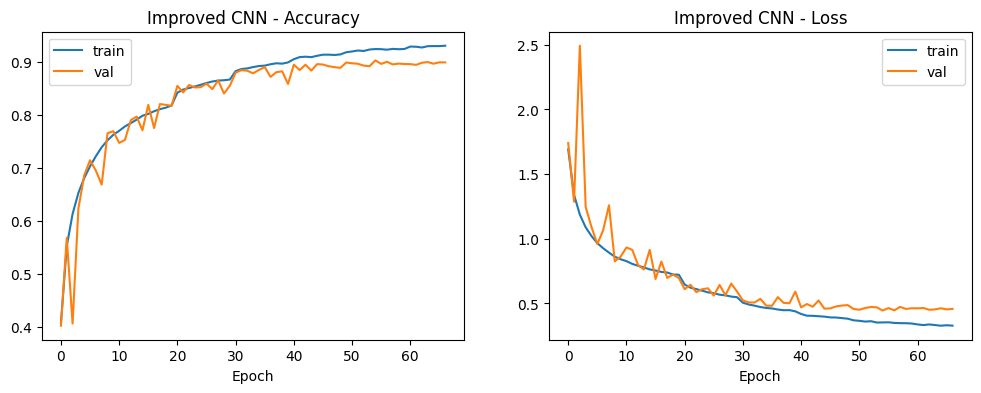

Improved CNN -> Test accuracy: 89.85%  |  Test loss: 0.4499


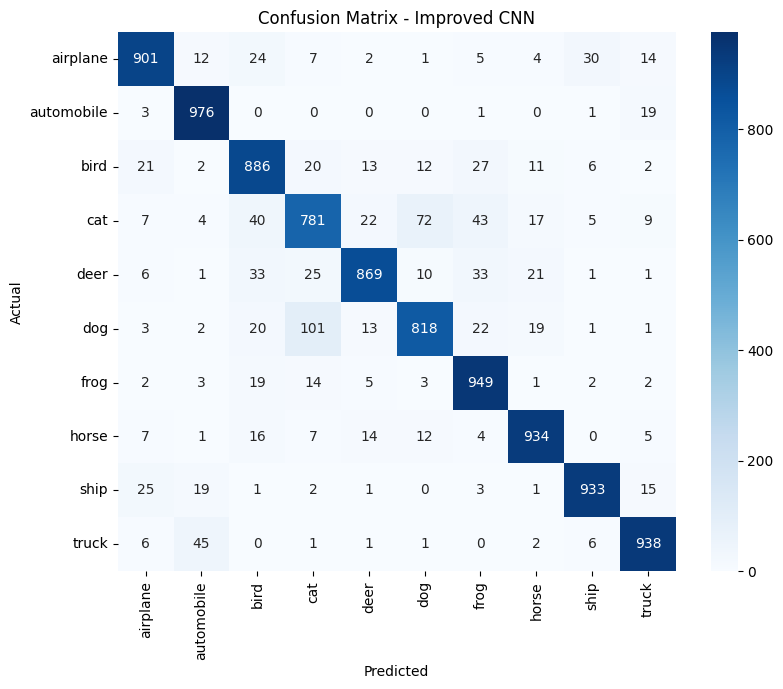

              precision    recall  f1-score   support

    airplane      0.918     0.901     0.910      1000
  automobile      0.916     0.976     0.945      1000
        bird      0.853     0.886     0.869      1000
         cat      0.815     0.781     0.798      1000
        deer      0.924     0.869     0.896      1000
         dog      0.881     0.818     0.848      1000
        frog      0.873     0.949     0.909      1000
       horse      0.925     0.934     0.929      1000
        ship      0.947     0.933     0.940      1000
       truck      0.932     0.938     0.935      1000

    accuracy                          0.898     10000
   macro avg      0.899     0.899     0.898     10000
weighted avg      0.899     0.898     0.898     10000



In [10]:
callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                      patience=4, min_lr=1e-5, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=12,
                                  restore_best_weights=True, verbose=1),
]

# This takes roughly 15-25 minutes on a Colab T4 GPU
hist_imp = improved.fit(x_tr, y_tr,
                        epochs=80, batch_size=128,
                        validation_data=(x_val, y_val),
                        callbacks=callbacks,
                        verbose=2)
plot_history(hist_imp, 'Improved CNN')
imp_acc = evaluate_model(improved, 'Improved CNN')

## 5. Small hyperparameter experiment (learning rate)

Quick 15-epoch runs to see how the learning rate affects results.
These are short runs, so accuracy will be lower than the full training above.


Training with learning rate = 0.01
Best val accuracy: 58.46%

Training with learning rate = 0.001
Best val accuracy: 80.36%

Training with learning rate = 0.0003
Best val accuracy: 79.06%


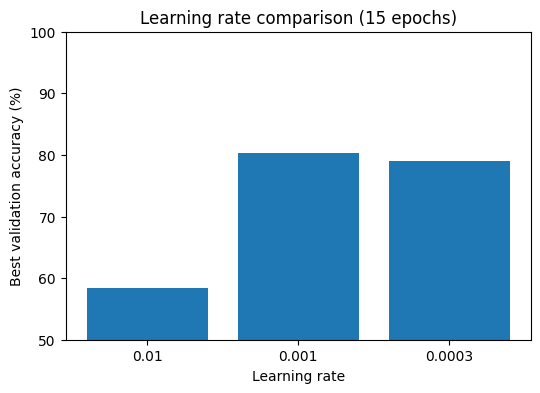

In [11]:
results = {}
for lr in [1e-2, 1e-3, 3e-4]:
    print(f"\nTraining with learning rate = {lr}")
    m = build_improved(lr=lr)
    h = m.fit(x_tr, y_tr, epochs=15, batch_size=128,
              validation_data=(x_val, y_val), verbose=0)
    results[lr] = max(h.history['val_accuracy'])
    print(f"Best val accuracy: {results[lr]*100:.2f}%")

plt.figure(figsize=(6, 4))
plt.bar([str(k) for k in results.keys()], [v * 100 for v in results.values()])
plt.ylabel('Best validation accuracy (%)')
plt.xlabel('Learning rate')
plt.title('Learning rate comparison (15 epochs)')
plt.ylim(50, 100)
plt.show()

## 6. Final comparison

,Model,Test accuracy (%)
0,Baseline,69.07
1,Baseline + Dropout,73.51
2,Baseline + Augmentation,78.20
3,Improved CNN (deeper + BN + dropout + aug + LR...,89.85


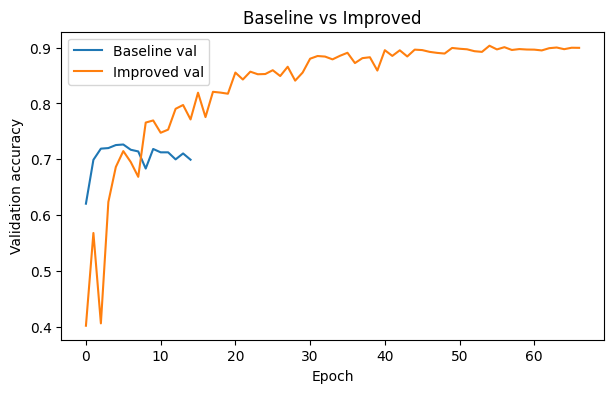

Total misclassified: 1015 out of 10000


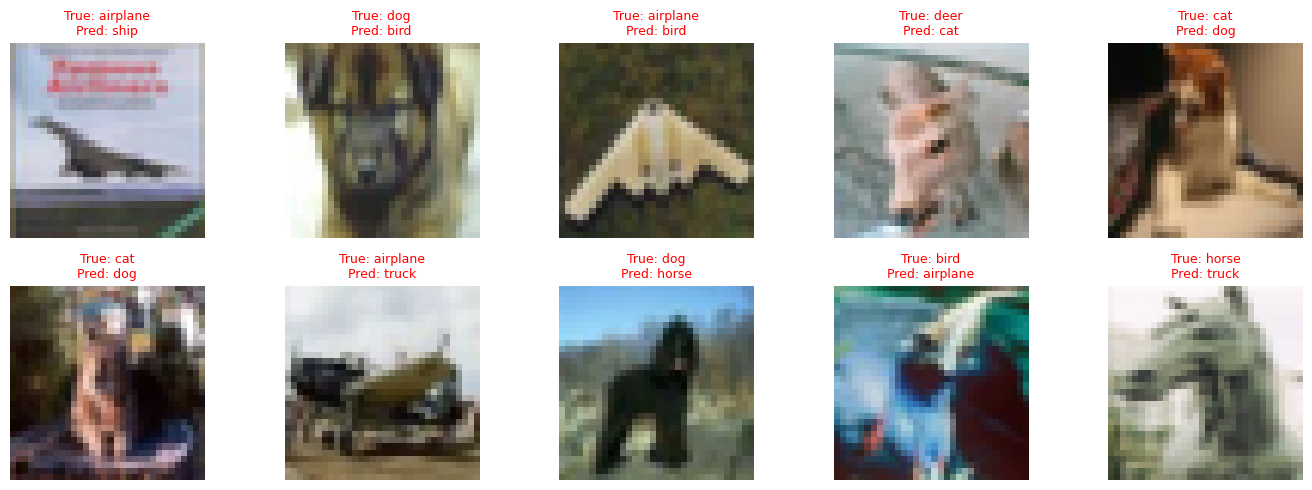

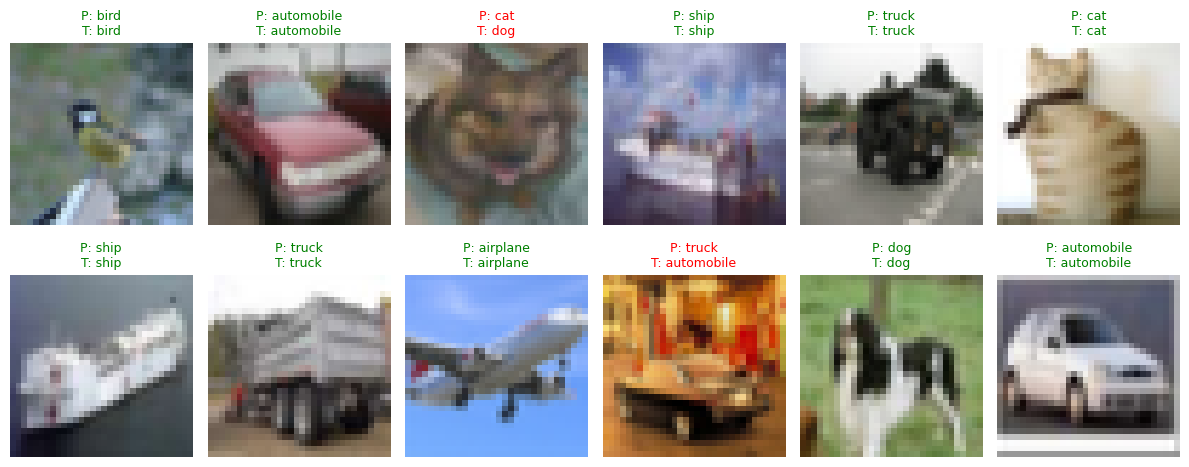

In [12]:
import pandas as pd

rows = []
for name, (m, h) in experiments.items():
    rows.append([name, m.evaluate(x_test, y_test, verbose=0)[1] * 100])
rows.append(['Improved CNN (deeper + BN + dropout + aug + LR schedule)', imp_acc * 100])
summary = pd.DataFrame(rows, columns=['Model', 'Test accuracy (%)']).round(2)
display(summary)

# learning-curve comparison: baseline vs improved
plt.figure(figsize=(7, 4))
plt.plot(hist_base.history['val_accuracy'], label='Baseline val')
plt.plot(hist_imp.history['val_accuracy'], label='Improved val')
plt.xlabel('Epoch'); plt.ylabel('Validation accuracy'); plt.legend()
plt.title('Baseline vs Improved')
plt.show()

# misclassified examples from the improved model
show_misclassified(improved, n=10)

# sample predictions (green = correct, red = wrong)
idx = np.random.choice(len(x_test), 12, replace=False)
preds = np.argmax(improved.predict(x_test[idx], verbose=0), axis=1)
raw_imgs = np.clip(x_test[idx] * std + mean, 0, 1)
plt.figure(figsize=(12, 5))
for n, k in enumerate(idx):
    plt.subplot(2, 6, n + 1)
    plt.imshow(raw_imgs[n])
    color = 'green' if preds[n] == y_test[k] else 'red'
    plt.title(f"P: {class_names[preds[n]]}\nT: {class_names[y_test[k]]}", color=color, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()